<a href="https://colab.research.google.com/github/Amonthep-Ux/Datamining/blob/main/Copy_of_%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [ ]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
q1 = np.percentile(water, 25)
q3 = np.percentile(water, 75)
iqr = q3 - q1
lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr
mask = (water < lo) | (water > hi)
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Lower fence (lo) = {lo}, Upper fence (hi) = {hi}")
print("ค่าที่อยู่นอกรั้ว:", water[mask])



Q1 = 175.5, Q3 = 185.5, IQR = 10.0
Lower fence (lo) = 160.5, Upper fence (hi) = 200.5
ค่าที่อยู่นอกรั้ว: [420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [ ]:
def iqr_outliers(x, k=1.5):
    # TODO
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน
# TODO 2.1
def iqr_outliers(x, k=1.5):
  arr = np.asarray(x ,dtype=float)
  q1 = np.percentile(arr, 25)
  q3 = np.percentile(arr, 75)
  iqr = q3 - q1
  lo = q1 - k * iqr
  hi = q3 + k * iqr
  mask = (arr < lo) | (arr > hi)
  return (mask, lo, hi)

# TODO 2.2
mask_15, lo_15, hi_15 = iqr_outliers(sales, k=1.5)
mask_3, lo_3, hi_3 = iqr_outliers(sales, k=3)

print("=== k = 1.5 (outlier ทั่วไป) ===")
print(f"Lower fence (lo) = {lo_15}, Upper fence (hi) = {hi_15}")
print("ค่าที่อยู่นอกรั้ว:", sales[mask_15])
print("=== k = 3 (extreme outlier) ===")
print(f"Lower fence (lo) = {lo_3}, Upper fence (hi) = {hi_3}")
print("ค่าที่อยู่นอกรั้ว:", sales[mask_3])
# TODO 2.3 assert
normal_data = np.array([10,12,11,13,12,14,11,],float)
mask_normal,_, _ = iqr_outliers(normal_data, k=1.5)
assert not mask_normal.any()

mask_ext, _, _ = iqr_outliers(sales, k=3)
assert np.array_equal(sales[mask_ext], np.array([120.0, 79.0]))

=== k = 1.5 (outlier ทั่วไป) ===
Lower fence (lo) = 38.375, Upper fence (hi) = 67.375
ค่าที่อยู่นอกรั้ว: [120.  79.  30.]
=== k = 3 (extreme outlier) ===
Lower fence (lo) = 27.5, Upper fence (hi) = 78.25
ค่าที่อยู่นอกรั้ว: [120.  79.]


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

ปลายทางหนวดล่าง: 46.0, ปลายหมวดบน: 61.0
ค่าที่อยู่นอกรั้ว: [ 30. 120.  79.]
ค่าที่อยู่นอกรั้ว: [120.  79.  30.]


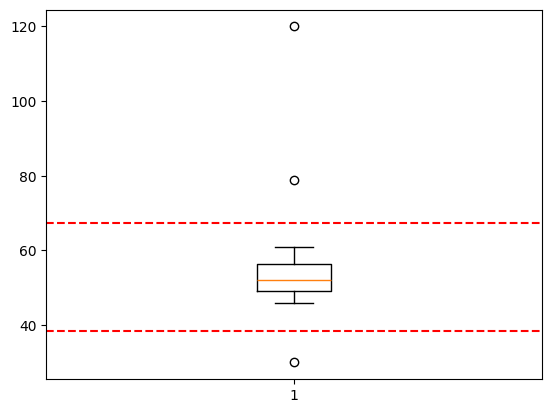

In [ ]:
# TODO ข้อ 3
mask_15, lo_15, hi_15 = iqr_outliers(sales, k=1.5)

#3.1
bp = plt.boxplot(sales, whis=1.5)
#3.2
plt.axhline(lo_15, color='r', linestyle='--')
plt.axhline(hi_15, color='r', linestyle='--')
#3.3
whiskers = bp['whiskers']
fliers = bp['fliers']
w_low_end = whiskers[0].get_ydata()[1]
w_high_end = whiskers[1].get_ydata()[1]
flier_vals = fliers[0].get_ydata()

print(f"ปลายทางหนวดล่าง: {w_low_end}, ปลายหมวดบน: {w_high_end}")
print("ค่าที่อยู่นอกรั้ว:", flier_vals)
print("ค่าที่อยู่นอกรั้ว:", sales[mask_15])

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [ ]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
mask_all, lo_all, hi_all = iqr_outliers(wage["wage_k"], k=1.5)
print(f"รวมทั้งหมด -> lo = {lo_all}, hi = {hi_all}")
print(f"พบ outlier ทั้งหมด: {mask_all.sum()} คน")
print(wage[mask_all])

# TODO 4.2–4.3
q1_grp = wage.groupby("occupation")["wage_k"].transform(
    lambda s: np.percentile(s, 25)
)
q3_grp = wage.groupby("occupation")["wage_k"].transform(
    lambda s: np.percentile(s, 75)
)
iqr_grp = q3_grp - q1_grp
lo_grp = q1_grp - 1.5 * iqr_grp
hi_grp = q3_grp + 1.5 * iqr_grp

mask_grp = (wage["wage_k"] < lo_grp) | (wage["wage_k"] > hi_grp)
print("\n=== Outlier รายอาชีพ (contextual anomaly) ===")
print(wage[mask_grp])

summary_table = (
    wage.groupby("occupation")["wage_k"]
    .agg(
        Q1=lambda s: np.percentile(s, 25),
        Q3=lambda s: np.percentile(s, 75),
    )
    .assign(
        IQR=lambda df: df.Q3 - df.Q1,
        lo=lambda df: df.Q1 - 1.5 * df.IQR,
        hi=lambda df: df.Q3 + 1.5 * df.IQR,
    )
)
print("\n=== ตารางสรุปเเต่ละอาชีพ ===")
print(summary_table)

รวมทั้งหมด -> lo = -56.0, hi = 130.0
พบ outlier ทั้งหมด: 0 คน
Empty DataFrame
Columns: [occupation, wage_k]
Index: []

=== Outlier รายอาชีพ (contextual anomaly) ===
   occupation  wage_k
7     cleaner      35
15      clerk       9

=== ตารางสรุปเเต่ละอาชีพ ===
               Q1     Q3   IQR      lo      hi
occupation                                    
cleaner     12.00  14.25  2.25   8.625  17.625
clerk       18.75  21.25  2.50  15.000  25.000
engineer    60.75  65.25  4.50  54.000  72.000
